# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import ThingsAndStuffDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 1543


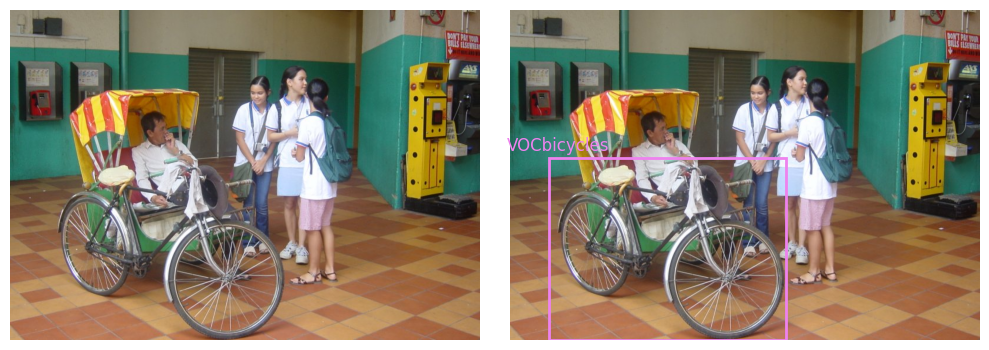

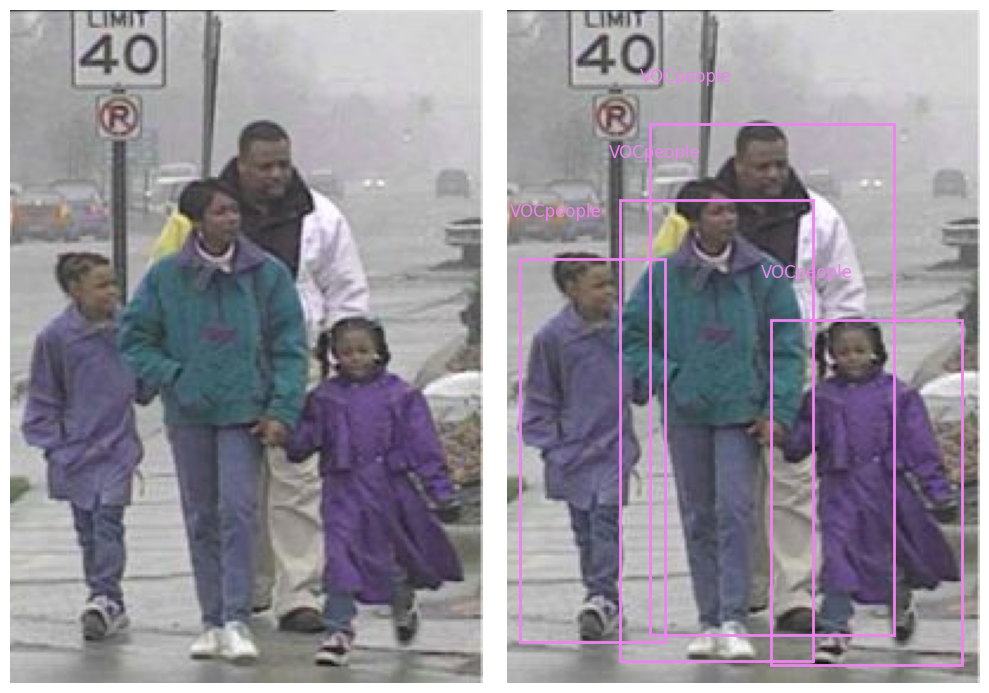

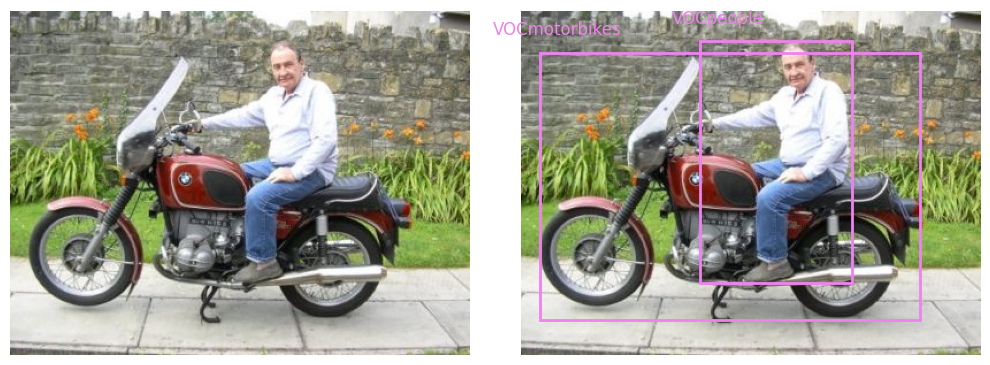

In [17]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/Images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/Groundtruth/"
}
dataset = ThingsAndStuffDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

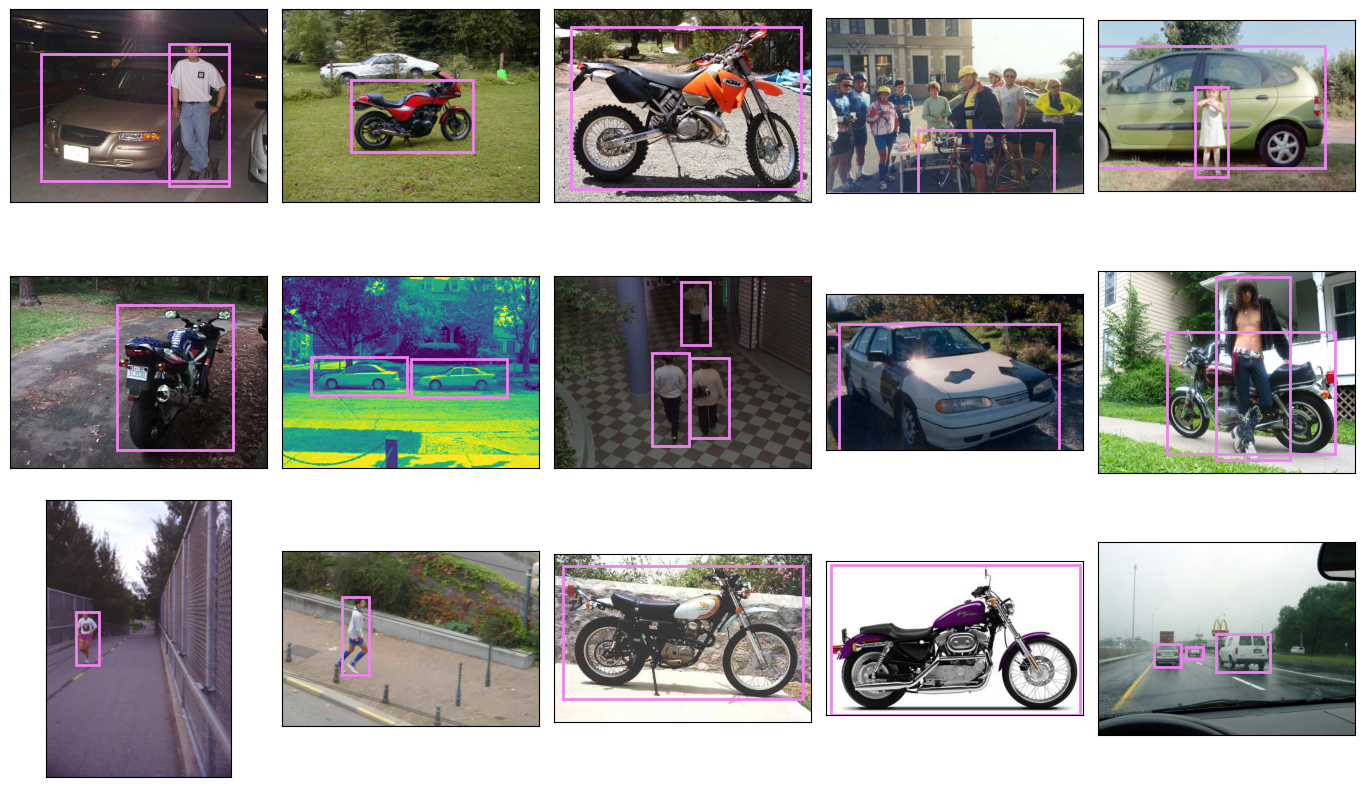

In [30]:
dataset.show_batch(15);

In [12]:
dataset.data_distribution_table()

,Label,Count
0,VOCbicycles,465
1,VOCcars,615
2,VOCmotorbikes,419
3,VOCpeople,1026


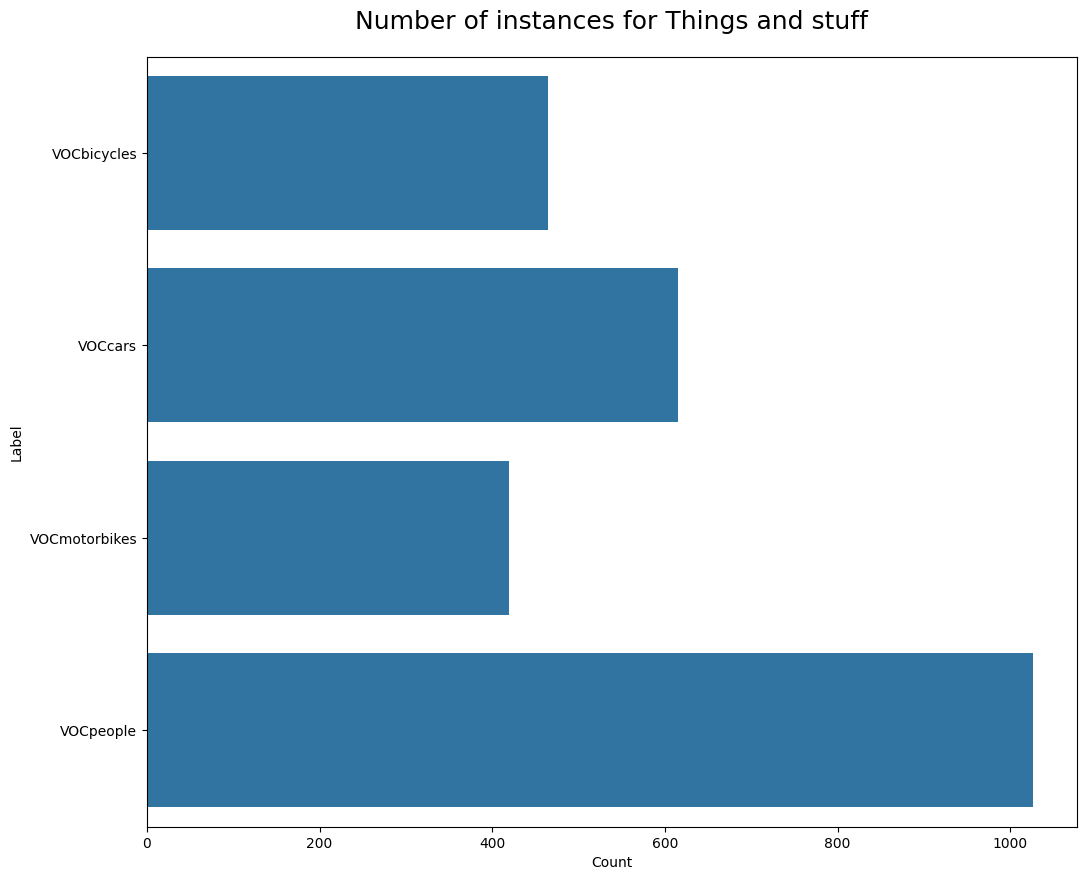

In [36]:
dataset.data_distribution_barchart();

## Load train data

In [18]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/train/Images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/train/Groundtruth/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = ThingsAndStuffDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 684


## Create the model

In [19]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/things_and_stuff/experiments/"
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [20]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-29 08:29:31,227 INFO Starting training.
training: 100%|██████████| 86/86 [00:28<00:00,  3.06it/s]
2025-04-29 08:29:59,362 INFO epoch: 1, time: 28, loss:  0.16436
testing on train set: 100%|██████████| 86/86 [00:15<00:00,  5.60it/s]
2025-04-29 08:30:16,946 INFO map:0.6566609144210815, map_50:0.9601642489433289, map_75:0.8261664509773254, map_small:0.5030620098114014, map_medium:0.601392924785614, map_large:0.6840763092041016, mar_1:0.6161683797836304, mar_10:0.7201758623123169, mar_100:0.7201758623123169, mar_small:0.5766233801841736, mar_medium:0.642307698726654, mar_large:0.7416749000549316, map_per_class:tensor(0.7343), tensor(0.6447), tensor(0.7072), tensor(0.5405), mar_100_per_class:tensor(0.7797), tensor(0.7138), tensor(0.7636), tensor(0.6237), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32)
training: 100%|██████████| 86/86 [00:28<00:00,  3.02it/s]
2025-04-29 08:30:45,386 INFO epoch: 2, time: 29

## Evaluate the model

In [21]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/test/Images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/things_and_stuff/test/Groundtruth/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = ThingsAndStuffDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 859


2025-04-29 08:43:25,838 INFO Loading checkpoint /home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar
2025-04-29 08:43:26,194 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 108/108 [00:19<00:00,  5.65it/s]


[{'map': 0.5111045241355896,
  'map_50': 0.7546558976173401,
  'map_75': 0.5786546468734741,
  'map_small': 0.3067784011363983,
  'map_medium': 0.33966732025146484,
  'map_large': 0.5564435720443726,
  'mar_1': 0.47613468766212463,
  'mar_10': 0.5913187265396118,
  'mar_100': 0.5915761590003967,
  'mar_small': 0.5666666626930237,
  'mar_medium': 0.4301608204841614,
  'mar_large': 0.6152559518814087,
  'map_per_class': [tensor(0.4692),
   tensor(0.5629),
   tensor(0.6124),
   tensor(0.3999)],
  'mar_100_per_class': [tensor(0.5167),
   tensor(0.6658),
   tensor(0.6698),
   tensor(0.5141)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32)]}]

## Predictions

2025-04-29 08:43:46,760 INFO Loading checkpoint /home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar
2025-04-29 08:43:47,096 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar at epoch 11


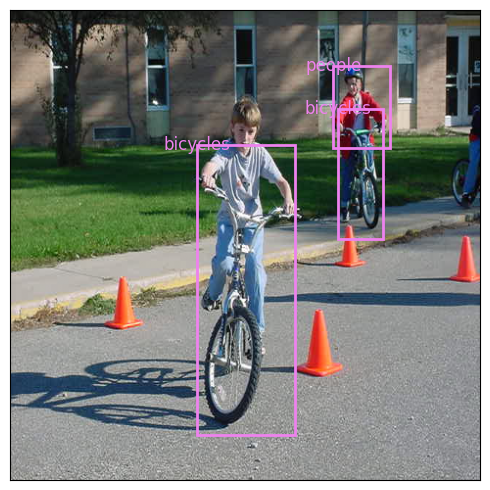

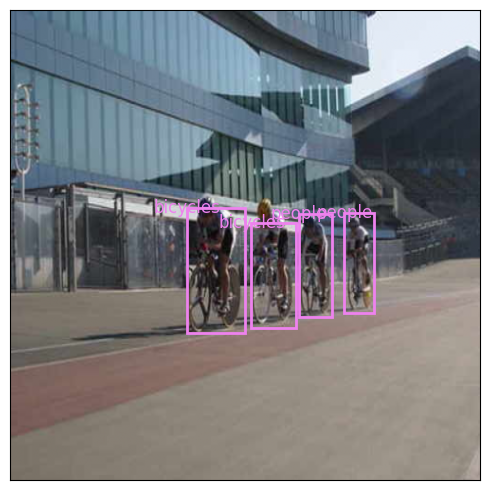

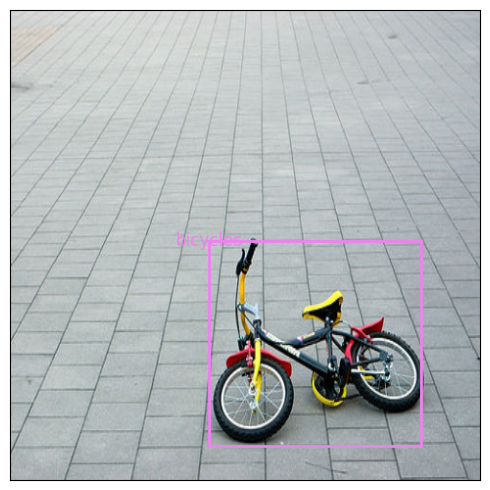

In [22]:
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/things_and_stuff/experiments/checkpoint.pth.tar"
labels = ["no-data","bicycles", "cars", "motorbikes", "people"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/things_and_stuff/test/Images/test2_bicycle_wwwaea1k12iausnwinnPictures2020032004Bicycle20RodeoBicycle20RodeoImages9.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/things_and_stuff/test/Images/test2_bicycle_todaibicyclemainjpphotohrRIMG00101.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/things_and_stuff/test/Images/test2_bicycle_wwwflickrcomphotos3310203236535340N00.png')
fig = model.detect_objects(image, labels, transform)